# European contract pricing with Tree

In [1]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable

## Create European contract payoff

In [2]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [3]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [4]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [5]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [6]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [7]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [ ]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

## Balanced Tree

In [8]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [9]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200'], ['0.820', '1.086', '1.440']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


## Delta is close to 0.5 for At The Money Forward option

In [10]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.508'], ['-0.000', '0.847']]
price tree:


[['0.075'], ['0.000', '0.150'], ['0.000', '0.000', '0.300']]

## Barrier options

In [11]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [14]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [12]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [15]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(np.float64(0.5), np.float64(0.5))
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## HW

=== Experiment 1: Same Contract, Different Step Counts ===
Steps | Target Price | Tree Price | Calibrated u | Down Factor d
--------------------------------------------------------------
    1 |    10.450584 |  10.450584 |     1.219728 |      0.882814
    2 |    10.450584 |  10.450584 |     1.175628 |      0.875002
    4 |    10.450584 |  10.450584 |     1.113772 |      0.911385
    8 |    10.450584 |  10.450584 |     1.076632 |      0.935907
   16 |    10.450584 |  10.450584 |     1.052727 |      0.953532
   32 |    10.450584 |  10.450584 |     1.036700 |      0.966428

=== Experiment 2: 1-Step Tree, Various Contracts ===
Expiry (T) | Strike (K) | Target Price | Tree Price | Calibrated u
-----------------------------------------------------------------
       0.5 |         90 |    13.498517 |  13.498517 |     1.176805
       0.5 |        100 |     6.888729 |   6.888729 |     1.141262
       0.5 |        110 |     2.906471 |   2.906471 |     1.159601
       1.0 |         90 |    16.699

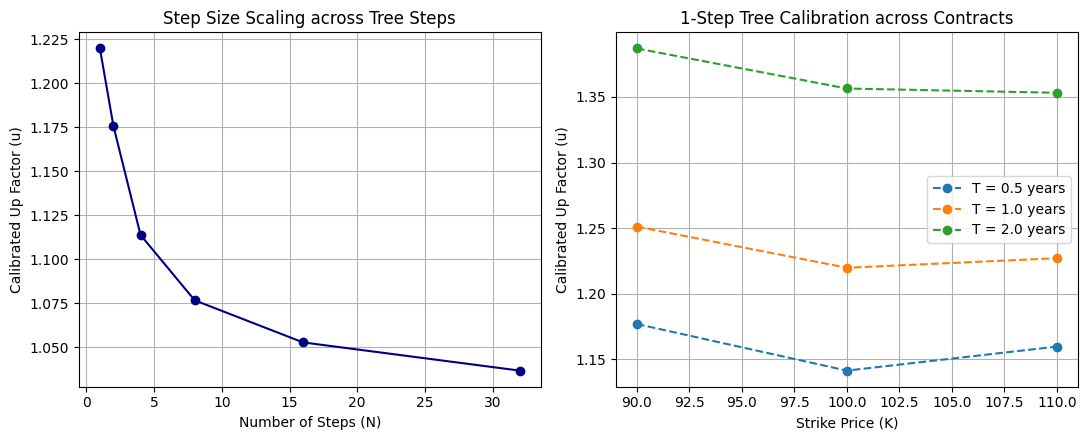

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import root_scalar
from scipy.stats import norm


# --- 1. Black-Scholes Formula (Only for generating target market prices) ---
def bsm_call(S0: float, K: float, T: float, r: float, sigma: float) -> float:
    """Calculates European Call price using Black-Scholes formula for benchmark targets."""
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


# --- 2. Vectorized Pricing in Balanced Binomial Tree ---
def price_tree(
    S0: float,
    K: float,
    T: float,
    r: float,
    u: float,
    steps: int,
    option_type: str = "call",
) -> float:
    """Prices a European option on a Balanced Binomial Tree (p = 0.5) using NumPy vectorization."""
    dt = T / steps
    growth = np.exp(r * dt)
    d = 2 * growth - u  # Risk-neutral probability p = 0.5 condition

    # Terminal stock prices at maturity T
    k = np.arange(steps + 1)
    ST = S0 * (u**k) * (d ** (steps - k))

    # Payoff at maturity
    if option_type == "call":
        values = np.maximum(ST - K, 0.0)
    else:
        values = np.maximum(K - ST, 0.0)

    # Backward induction (discounting with p = 0.5)
    discount = np.exp(-r * dt)
    for _ in range(steps):
        values = 0.5 * discount * (values[:-1] + values[1:])

    return values[0]


# --- 3. Robust Calibration Function ---
def calibrate_tree(
    target_price: float,
    S0: float,
    K: float,
    T: float,
    r: float,
    steps: int,
    option_type: str = "call",
) -> float:
    """Calibrates up-factor 'u' using exact theoretical bounds and root_scalar."""
    dt = T / steps
    growth = np.exp(r * dt)

    # Theoretical bounds for no-arbitrage (d > 0 and u > growth)
    u_min = growth + 1e-6
    u_max = 2 * growth - 1e-6

    # Root finding problem: Model Price - Target Price = 0
    objective = (
        lambda u: price_tree(S0, K, T, r, u, steps, option_type) - target_price
    )

    res = root_scalar(objective, bracket=[u_min, u_max], method="brentq")
    return res.root


# --- 4. Demonstrations & Experiments ---

S0 = 100.0
r = 0.05
sigma_market = 0.20  # Implied market volatility for generating prices

# Experiment 1: Same contract (K=100, T=1), varying tree steps N
K_base, T_base = 100.0, 1.0
target_base = bsm_call(S0, K_base, T_base, r, sigma_market)
step_counts = [1, 2, 4, 8, 16, 32]
u_vs_steps = []

print("=== Experiment 1: Same Contract, Different Step Counts ===")
print("Steps | Target Price | Tree Price | Calibrated u | Down Factor d")
print("-" * 62)

for N in step_counts:
    u_calib = calibrate_tree(target_base, S0, K_base, T_base, r, N)
    d_calib = 2 * np.exp(r * (T_base / N)) - u_calib
    model_p = price_tree(S0, K_base, T_base, r, u_calib, N)
    u_vs_steps.append(u_calib)

    print(
        f"{N:5d} | {target_base:12.6f} | {model_p:10.6f} | {u_calib:12.6f} | {d_calib:13.6f}"
    )

# Experiment 2: 1-step tree calibration across different Strikes and Expiries
strikes = [90, 100, 110]
expiries = [0.5, 1.0, 2.0]

print("\n=== Experiment 2: 1-Step Tree, Various Contracts ===")
print("Expiry (T) | Strike (K) | Target Price | Tree Price | Calibrated u")
print("-" * 65)

plt.figure(figsize=(11, 4.5))

# Plot 1: Step Size vs Number of Steps
plt.subplot(1, 2, 1)
plt.plot(step_counts, u_vs_steps, "o-", color="navy")
plt.xlabel("Number of Steps (N)")
plt.ylabel("Calibrated Up Factor (u)")
plt.title("Step Size Scaling across Tree Steps")
plt.grid(True)

# Plot 2: 1-Step Tree Calibration across Strikes/Expiries
plt.subplot(1, 2, 2)
for T in expiries:
    u_factors = []
    for K in strikes:
        target = bsm_call(S0, K, T, r, sigma_market)
        u_calib = calibrate_tree(target, S0, K, T, r, steps=1)
        u_factors.append(u_calib)
        model_p = price_tree(S0, K, T, r, u_calib, steps=1)
        print(
            f"{T:10.1f} | {K:10d} | {target:12.6f} | {model_p:10.6f} | {u_calib:12.6f}"
        )

    plt.plot(strikes, u_factors, "o--", label=f"T = {T} years")

plt.xlabel("Strike Price (K)")
plt.ylabel("Calibrated Up Factor (u)")
plt.title("1-Step Tree Calibration across Contracts")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()